Module 4 Assignment: Structure-Based Druggability of parkinsons.


In [1]:
DISEASE = "parkinsons"

TARGETS = {
    "MAP4K4": "O95819",
    "SNCA":   "P37840",
}
TARGET_INFO = {    
    "MAP4K4": {
        "module2_rank": 4, 
        "why": "MAP4K4 was chosen because it exhibited the largest significant protein change (log2FC 0.356) in Module 2 and rose to rank 1 after re-ranking, and its kinase domain has available crystals with a bound inhibitor (4U43) to validate the predicted pocket against a real ligand."
    },    
    "SNCA":   {
        "module2_rank": 3, 
        "why": "SNCA was chosen because it maintained a strong rank 3 across pipeline modules with robust significance (p_sm 0.023, p_ab 0.001), and it provides a unique test case as the primary Lewy body protein with an experimental structure (1XQ8) despite being intrinsically disordered."
    },
}
PDB = {
    "MAP4K4": ("4U43", "A"),   # kinase domain + inhibitor, 2.18 Å X-ray; chain A of two
    "SNCA":   ("1XQ8", "A"),   # check on rcsb.org: method, residue range, models
}

In [2]:
import json, shutil, subprocess, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

STRUCT = Path("structures"); STRUCT.mkdir(exist_ok=True)
assert set(TARGETS) == set(TARGET_INFO) == set(PDB), "TARGETS, TARGET_INFO and PDB must list the same genes"
if any(acc == "P00000" for acc in TARGETS.values()):
    raise ValueError("Set your two targets' UniProt accessions in the settings cell first.")

# ---------------- Helper functions (provided; from lab Part 2 and the demo) ----------------
def require(**kw):
    for name, val in kw.items():
        if val is Ellipsis:
            raise NotImplementedError(f"Complete the TODO above: `{name}` is still `...`")

def download(url, path):
    if path.exists() and path.stat().st_size > 0:
        return path
    req = urllib.request.Request(url, headers={"User-Agent": "BIOT6900-course-notebook"})
    with urllib.request.urlopen(req, timeout=60) as r:
        path.write_bytes(r.read())
    return path

def fetch_alphafold(acc):
    pdb_path, pae_path = STRUCT / f"AF-{acc}.pdb", STRUCT / f"AF-{acc}-pae.json"
    if pdb_path.exists() and pae_path.exists():
        return pdb_path, pae_path
    urls = []
    try:
        req = urllib.request.Request(f"https://alphafold.ebi.ac.uk/api/prediction/{acc}",
                                     headers={"User-Agent": "BIOT6900-course-notebook"})
        with urllib.request.urlopen(req, timeout=60) as r:
            entry = json.loads(r.read())[0]
        urls.append((entry["pdbUrl"], entry["paeDocUrl"]))
    except Exception as e:
        print(f"  API lookup failed for {acc} ({type(e).__name__}); trying direct file names")
    for v in ("v6", "v4"):
        base = f"https://alphafold.ebi.ac.uk/files/AF-{acc}-F1"
        urls.append((f"{base}-model_{v}.pdb", f"{base}-predicted_aligned_error_{v}.json"))
    for pu, eu in urls:
        try:
            download(pu, pdb_path); download(eu, pae_path)
            return pdb_path, pae_path
        except Exception:
            continue
    raise RuntimeError(f"Could not download {acc}: download by hand from https://alphafold.ebi.ac.uk/entry/{acc}")

def read_pdb(path, chain=None):
    rows = []
    for line in open(path):
        if line.startswith(("ATOM", "HETATM")):
            if line[16] not in (" ", "A") or (chain and line[21] != chain):
                continue
            rows.append({"record": line[:6].strip(), "atom": line[12:16].strip(), "resname": line[17:20].strip(),
                         "chain": line[21], "resnum": int(line[22:26]), "icode": line[26].strip(),
                         "x": float(line[30:38]), "y": float(line[38:46]), "z": float(line[46:54]),
                         "b": float(line[60:66]) if line[60:66].strip() else 0.0, "element": line[76:78].strip()})
        elif line.startswith("ENDMDL"):
            break
    return pd.DataFrame(rows)

def load_pae(path):
    js = json.load(open(path)); js = js[0] if isinstance(js, list) else js
    if "predicted_aligned_error" in js:
        return np.array(js["predicted_aligned_error"], dtype=float)
    n = int(max(js["residue1"])); return np.array(js["distance"], dtype=float).reshape(n, n)

def band(v):
    return "Very high" if v > 90 else "Confident" if v > 70 else "Low" if v > 50 else "Very low"
BAND_COLOUR = {"Very high": "#0053D6", "Confident": "#65CBF3", "Low": "#FFDB13", "Very low": "#FF7D45"}

def runs_below(values, resnums, cut=50, min_len=10):
    out, start = [], None
    for i, flag in enumerate(np.append(np.asarray(values) < cut, False)):
        if flag and start is None: start = i
        elif not flag and start is not None:
            if i - start >= min_len: out.append(f"{resnums[start]}-{resnums[i-1]}")
            start = None
    return ", ".join(out) or "none"

def find_domains(pae, plddt, pae_cut=8, min_size=20):
    ok = np.where(np.asarray(plddt) >= 70)[0]
    sub = pae[np.ix_(ok, ok)]; linked = (sub < pae_cut) & (sub.T < pae_cut)
    label, cur = -np.ones(len(ok), int), 0
    for s0 in range(len(ok)):
        if label[s0] >= 0: continue
        stack = [s0]; label[s0] = cur
        while stack:
            k = stack.pop()
            for m in np.where(linked[k] & (label < 0))[0]:
                label[m] = cur; stack.append(m)
        cur += 1
    out = [(ok[label == c].min() + 1, ok[label == c].max() + 1, int((label == c).sum())) for c in range(cur) if (label == c).sum() >= min_size]
    return pd.DataFrame(out, columns=["start", "end", "confident_residues"])

THREE = {"ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E", "GLY": "G", "HIS": "H",
         "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F", "PRO": "P", "SER": "S", "THR": "T", "TRP": "W",
         "TYR": "Y", "VAL": "V"}
def ca_table(df):
    ca = df[(df.atom == "CA") & (df.record == "ATOM")].drop_duplicates(["resnum", "icode"]).reset_index(drop=True)
    ca["aa"] = ca.resname.map(THREE).fillna("X")
    return ca

def global_align(a, b, match=2, mismatch=-1, gap=-2):
    # Needleman-Wunsch: list of (i, j) aligned index pairs
    n, m = len(a), len(b)
    S = np.zeros((n + 1, m + 1)); S[:, 0] = np.arange(n + 1) * gap; S[0, :] = np.arange(m + 1) * gap
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            S[i, j] = max(S[i-1, j-1] + (match if a[i-1] == b[j-1] else mismatch), S[i-1, j] + gap, S[i, j-1] + gap)
    i, j, pairs = n, m, []
    while i > 0 and j > 0:
        if S[i, j] == S[i-1, j-1] + (match if a[i-1] == b[j-1] else mismatch):
            pairs.append((i - 1, j - 1)); i -= 1; j -= 1
        elif S[i, j] == S[i-1, j] + gap: i -= 1
        else: j -= 1
    return pairs[::-1]

def kabsch(P, Q):
    # Rotation R and shift t so that P @ R + t best matches Q, plus the RMSD
    Pc, Qc = P.mean(0), Q.mean(0)
    U, S_, Vt = np.linalg.svd((P - Pc).T @ (Q - Qc))
    d = np.sign(np.linalg.det(U @ Vt)); R = U @ np.diag([1, 1, d]) @ Vt
    rmsd = float(np.sqrt((((P - Pc) @ R - (Q - Qc)) ** 2).sum(1).mean()))
    return R, Qc - Pc @ R, rmsd

def run_fpocket(pdb_path):
    out_dir = pdb_path.parent / f"{pdb_path.stem}_out"
    if not out_dir.exists():
        subprocess.run(["fpocket", "-f", str(pdb_path)], check=True, capture_output=True)
    pockets, cur = [], None
    for line in (out_dir / f"{pdb_path.stem}_info.txt").read_text().splitlines():
        if line.startswith("Pocket"):
            cur = {"pocket": int(line.split()[1])}; pockets.append(cur)
        elif cur is not None and ":" in line:
            key, val = [s.strip() for s in line.split(":", 1)]
            if key in ("Druggability Score", "Volume"): cur[key] = float(val)
    for p in pockets:
        p["lining_residues"] = sorted(read_pdb(out_dir / "pockets" / f"pocket{p['pocket']}_atm.pdb").resnum.unique().tolist())
    return pd.DataFrame(pockets)
print("Settings and helpers loaded for:", ", ".join(f"{g} ({a})" for g, a in TARGETS.items()))

Settings and helpers loaded for: MAP4K4 (O95819), SNCA (P37840)


## Step 2 · Download the AlphaFold model and PAE file

In [3]:
files, atoms, ca, pae = {}, {}, {}, {}
for gene, acc in TARGETS.items():
    files[gene] = fetch_alphafold(acc)
    atoms[gene] = read_pdb(files[gene][0])
    ca[gene] = ca_table(atoms[gene])
    pae[gene] = load_pae(files[gene][1])
    print(f"{gene} ({acc}): {len(ca[gene])} residues | PAE {pae[gene].shape}")

MAP4K4 (O95819): 1239 residues | PAE (1239, 1239)
SNCA (P37840): 140 residues | PAE (140, 140)


## Step 3 · Read pLDDT

The plot is provided. **TODO:** build the summary table: mean pLDDT, % above 90, % below 50, and the stretches of 10+ residues below 50 (use `runs_below`).

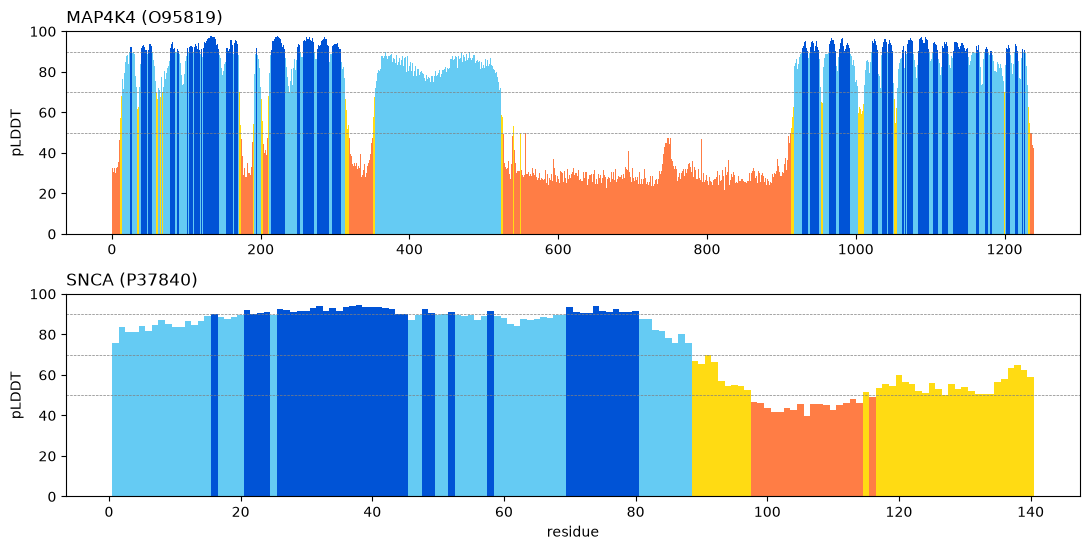

,gene,residues,mean_pLDDT,pct_above_90,pct_below_50,disordered_stretches
0,MAP4K4,1239,65.5,23.4,36.6,"1-11, 174-189, 319-350, 526-539, 550-912"
1,SNCA,140,75.2,28.6,12.9,98-114


In [4]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(11, 2.8 * len(TARGETS)), squeeze=False)
for ax, gene in zip(axes[:, 0], TARGETS):
    c = ca[gene]
    ax.bar(c.resnum, c.b, color=c.b.apply(band).map(BAND_COLOUR), width=1.0)
    for y in (50, 70, 90): ax.axhline(y, color="grey", lw=0.5, ls="--")
    ax.set_ylim(0, 100); ax.set_ylabel("pLDDT"); ax.set_title(f"{gene} ({TARGETS[gene]})", loc="left")
axes[-1, 0].set_xlabel("residue"); plt.tight_layout(); plt.show()

# Step 3 summary: one row per target
plddt_summary = pd.DataFrame([{
    "gene": g,
    "residues": len(ca[g]),
    "mean_pLDDT": round(ca[g].b.mean(), 1),
    "pct_above_90": round((ca[g].b > 90).mean() * 100, 1),
    "pct_below_50": round((ca[g].b < 50).mean() * 100, 1),
    "disordered_stretches": runs_below(ca[g].b.values, ca[g].resnum.values),
} for g in TARGETS])
require(plddt_summary=plddt_summary)
plddt_summary

## Step 4 · Read PAE and find domains

Heatmaps are provided. **TODO:** run `find_domains` for each target, and for any target with two or more domains compute the **mean PAE between the first two domains** (low = arrangement confident, high = uncertain).

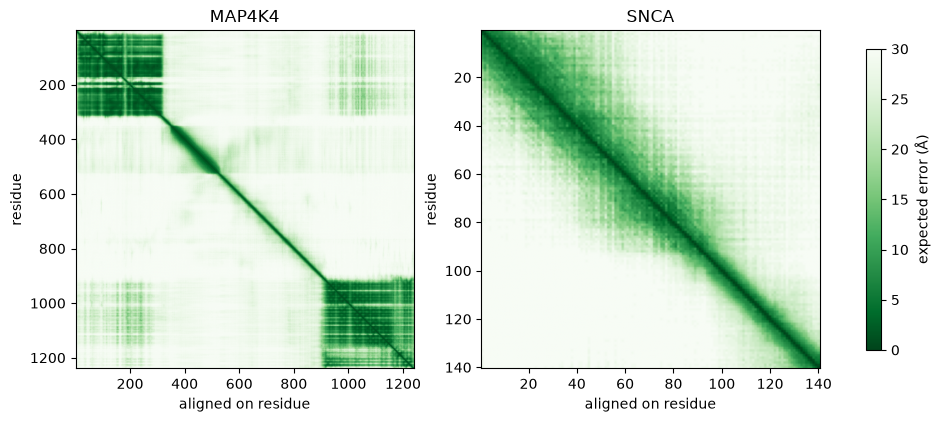


MAP4K4: 3 confident domain(s); mean PAE between domains 1 and 2: 28.1 Å
 start  end  confident_residues
    14  313                 261
   354  522                 169
   917 1231                 299

SNCA: 1 confident domain(s); mean PAE between domains 1 and 2: nan Å
 start  end  confident_residues
     1   88                  88


In [5]:
fig, axes = plt.subplots(1, len(TARGETS), figsize=(6 * len(TARGETS), 4.6), squeeze=False)
for ax, gene in zip(axes[0], TARGETS):
    n = pae[gene].shape[0]
    im = ax.imshow(pae[gene], cmap="Greens_r", vmin=0, vmax=30, extent=[0.5, n + 0.5, n + 0.5, 0.5])
    ax.set_title(gene); ax.set_xlabel("aligned on residue"); ax.set_ylabel("residue")
plt.colorbar(im, ax=axes, label="expected error (Å)", shrink=0.85); plt.show()

domains, inter_pae = {}, {}
for g in TARGETS:
    domains[g] = find_domains(pae[g], ca[g].b.values)
    if len(domains[g]) >= 2:
        d1, d2 = domains[g].iloc[0], domains[g].iloc[1]
        i1 = np.arange(d1.start - 1, d1.end)
        i2 = np.arange(d2.start - 1, d2.end)
        between = (pae[g][np.ix_(i1, i2)].mean() + pae[g][np.ix_(i2, i1)].mean()) / 2
        inter_pae[g] = round(float(between), 1)
    else:
        inter_pae[g] = np.nan

for g in TARGETS:
    require(domains=domains[g], inter_pae=inter_pae[g])
    print(f"\n{g}: {len(domains[g])} confident domain(s); mean PAE between domains 1 and 2: {inter_pae[g]} Å")
    print(domains[g].to_string(index=False))

In [6]:
for g in TARGETS:
    d = domains[g]
    for a in range(len(d)):
        for b in range(a + 1, len(d)):
            i1 = np.arange(d.start.iloc[a] - 1, d.end.iloc[a])
            i2 = np.arange(d.start.iloc[b] - 1, d.end.iloc[b])
            m = (pae[g][np.ix_(i1, i2)].mean() + pae[g][np.ix_(i2, i1)].mean()) / 2
            print(f"{g}: domain {a+1} ({d.start.iloc[a]}-{d.end.iloc[a]}) vs domain {b+1} "
                  f"({d.start.iloc[b]}-{d.end.iloc[b]}): mean PAE {m:.1f} Å")

MAP4K4: domain 1 (14-313) vs domain 2 (354-522): mean PAE 28.1 Å
MAP4K4: domain 1 (14-313) vs domain 3 (917-1231): mean PAE 25.4 Å
MAP4K4: domain 2 (354-522) vs domain 3 (917-1231): mean PAE 28.7 Å


**In your report:** which regions would you trust for pocket analysis? Use the decision table (lecture slide 12).

## Step 5 · Compare with an experimental structure

For each target with a PDB entry: pair residues **by sequence alignment** (numbering often differs), superimpose on **identical, confident** pairs (pLDDT ≥ 70), and report the RMSD. If the target has two or more domains with high PAE between them, also report RMSD **per domain**.

**Changes I made in Step 5:** (1) replaced `global_align` with `semiglobal_align`, because 4U43 covers only the kinase domain and the global alignment paired some crystal residues with the C-terminal domain (RMSD 20.99 Å before the fix, 1.19 Å after); (2) added a guard that skips superposition when fewer than 10 usable pairs exist; (3) added per-helix RMSD for SNCA (next cell), because the whole-protein value is dominated by the arrangement of its two helices. Helix ranges from: [Ulmer TS, Bax A, Cole NB, Nussbaum RL (2005). Structure and dynamics of micelle-bound human alpha-synuclein. J Biol Chem 280(10):9595–9603 (PMID 15615727), the paper reporting PDB 1XQ8.].

In [7]:
def semiglobal_align(a, b, match=2, mismatch=-1, gap=-2):
    # Like global_align, but unmatched residues at the ends of `a` (the full-length model) cost nothing,
    # so a short crystal fragment is not spread across the whole protein.
    n, m = len(a), len(b)
    S = np.zeros((n + 1, m + 1)); S[0, :] = np.arange(m + 1) * gap
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            S[i, j] = max(S[i-1, j-1] + (match if a[i-1] == b[j-1] else mismatch), S[i-1, j] + gap, S[i, j-1] + gap)
    i, j, pairs = int(np.argmax(S[:, m])), m, []
    while i > 0 and j > 0:
        if S[i, j] == S[i-1, j-1] + (match if a[i-1] == b[j-1] else mismatch):
            pairs.append((i - 1, j - 1)); i -= 1; j -= 1
        elif S[i, j] == S[i-1, j] + gap: i -= 1
        else: j -= 1
    return pairs[::-1]


comparison, deviation, exp_map = {}, {}, {}
for gene, entry in PDB.items():
    if entry is None:
        print(f"{gene}: no experimental structure; assess on confidence alone (say so in your report).")
        comparison[gene] = {"pdb_id": "none", "rmsd_confident": np.nan, "pairs_used": 0}
        continue
    pdb_id, chain = entry
    xt = read_pdb(download(f"https://files.rcsb.org/download/{pdb_id}.pdb", STRUCT / f"{pdb_id}.pdb"), chain=chain)
    xca, aca = ca_table(xt), ca[gene]
    pairs = semiglobal_align("".join(aca.aa), "".join(xca.aa))
    exp_map[gene] = {(xca.resnum[j], xca.icode[j]): aca.resnum[i] for i, j in pairs}   # PDB -> UniProt numbering
    A, X = aca[["x", "y", "z"]].to_numpy(), xca[["x", "y", "z"]].to_numpy()

    # Keep pairs where the amino acids match AND AlphaFold is confident (pLDDT >= 70), then superimpose
    use = [(i, j) for i, j in pairs if aca.aa[i] == xca.aa[j] and aca.b[i] >= 70]
    if len(use) < 10:
        print(f"{gene}: only {len(use)} identical + confident pairs - too few to superimpose; report this.")
        comparison[gene] = {"pdb_id": pdb_id, "rmsd_confident": np.nan, "pairs_used": len(use)}
        continue
    R, t, rmsd = kabsch(A[[i for i, _ in use]], X[[j for _, j in use]])
    require(use=use, rmsd=rmsd)
    moved = A @ R + t
    deviation[gene] = pd.Series({aca.resnum[i]: float(np.linalg.norm(moved[i] - X[j])) for i, j in use})
    comparison[gene] = {"pdb_id": pdb_id, "rmsd_confident": round(rmsd, 2), "pairs_used": len(use)}
    print(f"{gene} vs {pdb_id} chain {chain}: {len(pairs)} aligned pairs, {len(use)} identical and confident; RMSD {rmsd:.2f} Å")

    # Per-domain RMSD when the arrangement between domains is uncertain
    if len(domains[gene]) >= 2 and inter_pae[gene] > 10:
        for k, d in domains[gene].iterrows():
            sub = [(i, j) for i, j in use if d.start <= aca.resnum[i] <= d.end]
            if len(sub) >= 10:
                print(f"   domain {k + 1} ({d.start}-{d.end}): RMSD {kabsch(A[[i for i, _ in sub]], X[[j for _, j in sub]])[2]:.2f} Å over {len(sub)} residues")

MAP4K4 vs 4U43 chain A: 287 aligned pairs, 259 identical and confident; RMSD 1.19 Å
   domain 1 (14-313): RMSD 1.19 Å over 259 residues
SNCA vs 1XQ8 chain A: 140 aligned pairs, 88 identical and confident; RMSD 32.45 Å


In [8]:
SEGMENTS = {"SNCA": [(3, 37), (45, 92)]}   # helix ranges in 1XQ8: VERIFY on rcsb.org / the 1XQ8 paper and cite it

for gene, segs in SEGMENTS.items():
    pdb_id, chain = PDB[gene]
    xca = ca_table(read_pdb(STRUCT / f"{pdb_id}.pdb", chain=chain)); aca = ca[gene]
    pairs = semiglobal_align("".join(aca.aa), "".join(xca.aa))
    use = [(i, j) for i, j in pairs if aca.aa[i] == xca.aa[j] and aca.b[i] >= 70]
    A, X = aca[["x", "y", "z"]].to_numpy(), xca[["x", "y", "z"]].to_numpy()
    for s, e in segs:
        sub = [(i, j) for i, j in use if s <= aca.resnum[i] <= e]
        if len(sub) >= 10:
            r = kabsch(A[[i for i, _ in sub]], X[[j for _, j in sub]])[2]
            print(f"{gene} {s}-{e}: RMSD {r:.2f} Å over {len(sub)} confident residues")
        else:
            print(f"{gene} {s}-{e}: only {len(sub)} confident residues, not compared")

SNCA 3-37: RMSD 1.36 Å over 35 confident residues
SNCA 45-92: RMSD 3.77 Å over 44 confident residues


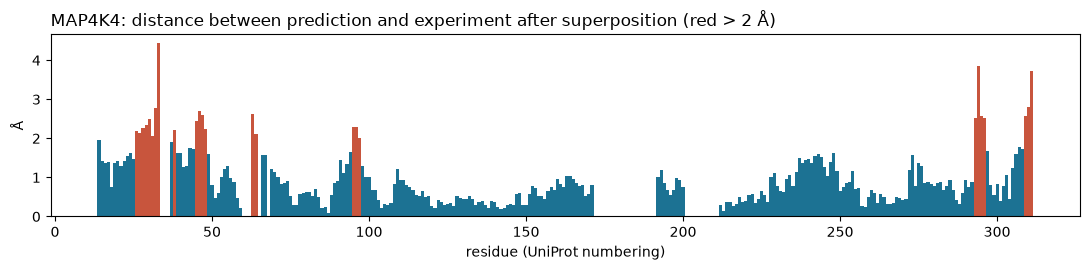

MAP4K4: residues that differ most: 33 (4.4 Å), 294 (3.8 Å), 311 (3.7 Å), 310 (2.8 Å), 32 (2.8 Å), 46 (2.7 Å)


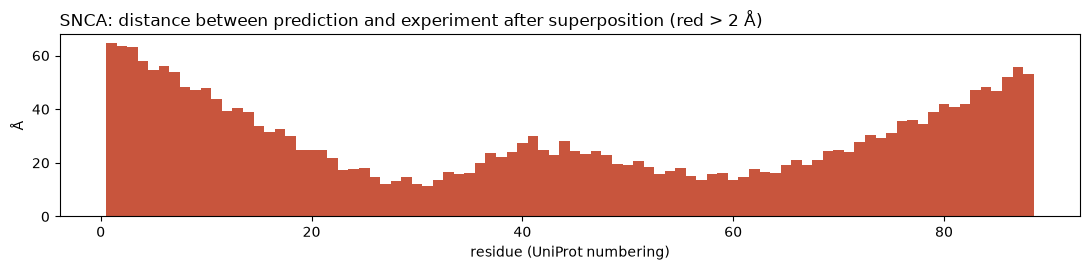

SNCA: residues that differ most: 1 (64.7 Å), 2 (63.7 Å), 3 (63.2 Å), 4 (57.8 Å), 6 (56.1 Å), 87 (55.8 Å)


In [9]:
for gene, dev in deviation.items():
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.bar(dev.index, dev.values, color=["#C8553D" if d > 2 else "#1C7293" for d in dev.values], width=1.0)
    ax.set_title(f"{gene}: distance between prediction and experiment after superposition (red > 2 Å)", loc="left")
    ax.set_xlabel("residue (UniProt numbering)"); ax.set_ylabel("Å"); plt.tight_layout(); plt.show()
    print(f"{gene}: residues that differ most:", ", ".join(f"{r} ({v:.1f} Å)" for r, v in dev.nlargest(6).items()))

## Step 6 · Detect and filter pockets

**TODO:** for each pocket, compute the mean pLDDT of the lining residues and the mean PAE among them, then apply the rules: **reject** if mean pLDDT < 70; **suspect** if PAE among the lining residues > 10 Å; otherwise **keep**. Show the top five by druggability score. Every pocket is kept (with its **rank** by score) for the ligand-site check below.

**Note:** fpocket cannot be installed on Windows. It was run in Google Colab (installed with micromamba from conda-forge); the output folders were zipped and extracted into `structures/` here. The Step 6 cell was edited so it reads this precomputed output instead of stopping.


In [10]:
import zipfile
zipfile.ZipFile(STRUCT / "fpocket_out.zip").extractall(STRUCT)
for acc in TARGETS.values():
    f = STRUCT / f"AF-{acc}_out" / f"AF-{acc}_info.txt"
    print(f, "->", "FOUND" if f.exists() else "MISSING")

structures\AF-O95819_out\AF-O95819_info.txt -> FOUND
structures\AF-P37840_out\AF-P37840_info.txt -> FOUND


In [11]:
# fpocket was run in Google Colab (Windows can't install it); the output folders were copied into structures/.
# run_fpocket() only calls fpocket if the output folder is missing, so it reads the precomputed results here.
have_output = all((STRUCT / f"AF-{acc}_out").exists() for acc in TARGETS.values())
if shutil.which("fpocket") is None and not have_output:
    raise RuntimeError("fpocket not found and no precomputed AF-<acc>_out folders in structures/.")

top_pockets, all_pockets = {}, {}
for gene in TARGETS:
    pk = run_fpocket(files[gene][0])
    plddt = ca[gene].set_index("resnum").b
    P = pae[gene]
    pk["mean_pLDDT"] = pk.lining_residues.apply(lambda r: round(float(plddt.reindex(r).mean()), 1))
    pk["PAE_within"] = pk.lining_residues.apply(
        lambda r: round(float(P[np.ix_(np.array(r) - 1, np.array(r) - 1)].mean()), 1))
    pk["verdict"] = np.where(pk.mean_pLDDT < 70, "reject: low confidence",
                    np.where(pk.PAE_within > 10, "suspect: lining not placed together", "keep"))
    require(verdict=pk["verdict"].iloc[0])
    pk["rank"] = pk["Druggability Score"].rank(ascending=False, method="first").astype(int)
    all_pockets[gene] = pk
    top_pockets[gene] = pk.sort_values("Druggability Score", ascending=False).head(5)
    print(f"\n{gene}: top five pockets by druggability score")
    print(top_pockets[gene].drop(columns="lining_residues").to_string(index=False))


MAP4K4: top five pockets by druggability score
 pocket  Druggability Score  Volume  mean_pLDDT  PAE_within                             verdict  rank
     95               0.204 678.386        72.9        11.7 suspect: lining not placed together     1
     60               0.103 423.984        72.6         7.9                                keep     2
     87               0.074 171.595        66.9        10.4              reject: low confidence     3
     91               0.035 409.427        87.7         1.8                                keep     4
     13               0.027 182.226        84.0         1.6                                keep     5

SNCA: top five pockets by druggability score
 pocket  Druggability Score  Volume  mean_pLDDT  PAE_within                verdict  rank
      1               0.949 472.677        89.4         7.4                   keep     1
      2               0.630 489.857        52.7         6.5 reject: low confidence     2
     10               0.497

### Ligand-site check *(provided)*

**If your experimental structure has a ligand bound,** the next cell takes **each** bound ligand in turn, finds the protein residues within 4.5 Å of it, converts them to UniProt numbering using your Step 5 alignment, and searches **every** pocket, not just the top five. For each ligand it reports how much of the site your best kept pocket covers, and which pocket covers it best, with that pocket's rank, score and verdict.

**In your report:** is your best **kept** pocket where the ligand sits? If there are several copies of a ligand, which one is in the functional site? If not, which pocket is, how does it rank, and why might fpocket score a real binding site low? (Large, open or polar sites, such as protease clefts, often score poorly.)

*Not counted as ligands:* water, metal ions, common crystallization additives (sulfate, glycerol and similar), and peptide or nucleic-acid partners deposited as a separate protein or DNA chain.

In [12]:
IGNORE_HET = {"HOH", "WAT", "DOD", "SO4", "PO4", "GOL", "EDO", "PEG", "PG4", "PGE", "1PE", "ACT", "FMT", "DMS",
              "MPD", "BME", "TRS", "EPE", "MES", "IMD", "CL", "NA", "K", "MG", "CA", "ZN", "MN", "FE", "CU", "CO",
              "NI", "CD", "HG", "IOD", "BR", "NO3", "NH4", "SCN", "UNX"}

def ligand_sites(pdb_path, chain, cutoff=4.5, min_atoms=6):
    """For each small-molecule ligand touching `chain`: the (resnum, icode) of chain residues within `cutoff` Å."""
    at = read_pdb(pdb_path)
    het = at[(at.record == "HETATM") & ~at.resname.isin(IGNORE_HET)]
    het = het[het.groupby(["chain", "resname", "resnum"]).x.transform("size") >= min_atoms]   # drop ions / tiny additives
    prot = at[(at.record == "ATOM") & (at.chain == chain)]
    sites = {}
    for (c, name, num), lig in het.groupby(["chain", "resname", "resnum"]):
        d = np.linalg.norm(prot[["x", "y", "z"]].to_numpy()[:, None] - lig[["x", "y", "z"]].to_numpy()[None], axis=2)
        near = (d < cutoff).any(1)
        if near.any():
            sites[f"{name} {c}{num}"] = set(zip(prot.resnum[near], prot.icode[near]))
    return sites

ligand_pockets = {}
for gene, entry in PDB.items():
    if entry is None:
        print(f"{gene}: no experimental structure, so no ligand-site check.\n"); continue
    pdb_id, chain = entry
    sites = ligand_sites(STRUCT / f"{pdb_id}.pdb", chain)
    if not sites:
        print(f"{gene}: {pdb_id} chain {chain} has no bound small-molecule ligand to check against.\n"); continue
    pk = all_pockets[gene]
    kept = pk[pk.verdict == "keep"].sort_values("Druggability Score", ascending=False)
    best = kept.iloc[0] if len(kept) else None
    rows = []
    for lig, contacts in sites.items():
        site = sorted({exp_map[gene][k] for k in contacts if k in exp_map[gene]})   # UniProt numbering
        if not site:
            print(f"  {lig}: its contact residues are not in the aligned region; skipped"); continue
        cover = pk.lining_residues.apply(lambda r: len(set(r) & set(site)) / len(site))
        top = pk.loc[cover.idxmax()]
        rows.append({"ligand": lig, "site_residues": len(site),
                     "best_kept_pocket_covers": round(float(cover[best.name]), 2) if best is not None else np.nan,
                     "site_pocket": int(top.pocket), "site_pocket_rank": int(top["rank"]),
                     "site_pocket_score": round(top["Druggability Score"], 3), "site_pocket_verdict": top.verdict,
                     "site_pocket_covers": round(float(cover.max()), 2), "residues": ", ".join(map(str, site))})
    ligand_pockets[gene] = pd.DataFrame(rows)
    print(f"{gene} vs {pdb_id} chain {chain}  |  best kept pocket: "
          + (f"{int(best.pocket)} (score {best['Druggability Score']:.3f}, rank {int(best['rank'])})" if best is not None else "none"))
    print(ligand_pockets[gene].drop(columns="residues").to_string(index=False))
    for r in rows:
        print(f"  {r['ligand']} site (UniProt numbering): {r['residues']}")
    print()


MAP4K4 vs 4U43 chain A  |  best kept pocket: 60 (score 0.103, rank 2)
  ligand  site_residues  best_kept_pocket_covers  site_pocket  site_pocket_rank  site_pocket_score    site_pocket_verdict  site_pocket_covers
3D8 A401             15                      0.0          122                31              0.002 reject: low confidence                0.87
  3D8 A401 site (UniProt numbering): 31, 33, 34, 39, 52, 54, 105, 106, 107, 108, 111, 158, 160, 170, 171

SNCA: 1XQ8 chain A has no bound small-molecule ligand to check against.



## Step 7 · Make a druggability call and export the summary

Choose one call per target: **"Structure supports a small-molecule pocket"**, **"Possible but uncertain"**, or **"No confident pocket: consider another modality"**. Justify it in your report.

In [13]:
pl = {g: ca[g].set_index("resnum").b for g in TARGETS}

for g in TARGETS:
    print(f"\n{g}: {len(domains[g])} confident domain(s) | inter-domain PAE: {inter_pae[g]}")
    for _, p in top_pockets[g].iterrows():
        r = p.lining_residues
        print(f"  pocket {p.pocket}: residues {min(r)}-{max(r)}, {len(r)} lining, {p.verdict}")

# Why was the inhibitor-site pocket rejected? Per-residue pLDDT of its lining (flag < 70)
site = all_pockets["MAP4K4"].set_index("pocket").loc[122]
print(f"\nMAP4K4 pocket 122: mean pLDDT {site.mean_pLDDT}, PAE_within {site.PAE_within}, score {site['Druggability Score']}")
print("  lining (residue:pLDDT, * = below 70):")
print("  " + ", ".join(f"{r}:{pl['MAP4K4'][r]:.0f}{'*' if pl['MAP4K4'][r] < 70 else ''}" for r in site.lining_residues))

# Which residues line SNCA pocket 1?
s1 = all_pockets["SNCA"].set_index("pocket").loc[1]
print(f"\nSNCA pocket 1 lining: {s1.lining_residues}")


MAP4K4: 3 confident domain(s) | inter-domain PAE: 28.1
  pocket 95: residues 182-1056, 19 lining, suspect: lining not placed together
  pocket 60: residues 431-637, 7 lining, keep
  pocket 87: residues 188-1059, 11 lining, reject: low confidence
  pocket 91: residues 228-254, 12 lining, keep
  pocket 13: residues 494-505, 5 lining, keep

SNCA: 1 confident domain(s) | inter-domain PAE: nan
  pocket 1: residues 48-63, 8 lining, keep
  pocket 2: residues 125-133, 8 lining, reject: low confidence
  pocket 10: residues 8-16, 5 lining, keep
  pocket 8: residues 62-67, 4 lining, keep
  pocket 9: residues 93-96, 4 lining, reject: low confidence

MAP4K4 pocket 122: mean pLDDT 67.9, PAE_within 11.1, score 0.002
  lining (residue:pLDDT, * = below 70):
  29:90, 31:85, 32:78, 33:73, 34:62*, 35:55*, 36:63*, 37:72, 39:89, 52:94, 54:90, 56:86, 57:83, 59:75, 61:67*, 62:68*, 64:71, 65:67*, 66:77, 68:70*, 69:73, 107:93, 108:92, 109:88, 111:92, 112:94, 114:93, 115:91, 118:91, 152:80, 153:85, 155:92, 157:

In [14]:
site_res = [int(x) for x in ligand_pockets["MAP4K4"].residues.iloc[0].split(", ")]
pl4 = ca["MAP4K4"].set_index("resnum").b
idx = np.array(site_res) - 1
print(f"Inhibitor-contact residues (4U43, 3D8): n={len(site_res)}, mean pLDDT {pl4.loc[site_res].mean():.1f}, "
      f"min {pl4.loc[site_res].min():.0f}, PAE among them {pae['MAP4K4'][np.ix_(idx, idx)].mean():.1f} Å")
p122 = all_pockets["MAP4K4"].set_index("pocket").loc[122, "lining_residues"]
extra = [r for r in p122 if r not in site_res]
print(f"Pocket 122: {len(p122)} lining residues, {len(extra)} of them do not touch the inhibitor; "
      f"C-terminal-domain residues among them: {[r for r in extra if r > 900]}")

Inhibitor-contact residues (4U43, 3D8): n=15, mean pLDDT 87.1, min 62, PAE among them 2.9 Å
Pocket 122: 71 lining residues, 58 of them do not touch the inhibitor; C-terminal-domain residues among them: [993, 1052, 1053, 1054, 1056]


In [15]:
CALLS = {
    "MAP4K4": "<one of the three phrases>",
    "SNCA":   "<one of the three phrases>",
}
assert set(CALLS) == set(TARGETS), "Give a call for every target"

rows = []
for g, acc in TARGETS.items():
    kept = top_pockets[g][top_pockets[g].verdict == "keep"]
    rows.append({"gene": g, "uniprot": acc, "module2_rank": TARGET_INFO[g]["module2_rank"],
                 "mean_pLDDT": plddt_summary.set_index("gene").loc[g, "mean_pLDDT"],
                 "pct_below_50": plddt_summary.set_index("gene").loc[g, "pct_below_50"],
                 "n_domains": len(domains[g]), "inter_domain_PAE": inter_pae[g],
                 "pdb_id": comparison[g]["pdb_id"], "rmsd_confident": comparison[g]["rmsd_confident"],
                 "best_pocket_score": round(kept["Druggability Score"].max(), 3) if len(kept) else np.nan,
                 "best_pocket_verdict": "keep" if len(kept) else top_pockets[g].verdict.iloc[0],
                 "druggability_call": CALLS[g]})
summary = pd.DataFrame(rows)
out_file = f"structure_assessment_{DISEASE}.csv"
summary.to_csv(out_file, index=False)
print("Wrote", out_file)
summary

Wrote structure_assessment_parkinsons.csv


,gene,uniprot,module2_rank,mean_pLDDT,pct_below_50,n_domains,inter_domain_PAE,pdb_id,rmsd_confident,best_pocket_score,best_pocket_verdict,druggability_call
0,MAP4K4,O95819,4,65.5,36.6,3,28.1,4U43,1.19,0.103,keep,<one of the three phrases>
1,SNCA,P37840,3,75.2,12.9,1,NaN,1XQ8,32.45,0.949,keep,<one of the three phrases>


## Step 8 · Anchor check: p53

The predicted p53 structure closely matches the experimental reference structure 1TUP chain B, with an RMSD of 0.68 Å across 192 confident residues (pLDDT ≥ 70), compared with 0.73 Å across all 194 residues, supporting good overall structural agreement despite localized deviations. The hotspot residues C176, H179, C238, and C242 coordinate zinc, with their reported distances to Zn ranging from 2.1 to 2.3 Å, whereas R248 and R273 directly contact DNA at 3.4 and 2.5 Å, respectively. These structural observations provide a functional basis for interpreting the Module 3 sequence-based variant scores: substitutions at zinc-ligand positions may disrupt metal coordination and protein stability, while DNA-contact substitutions may impair p53–DNA interactions. Y220 is an important exception because it lies far from both zinc and DNA and was among the less extreme hotspots, yet the Y220C mutation can create a druggable crevice, illustrating how a variant can affect structural properties without directly disrupting either interaction. Correctly interpreting this p53 anchor therefore helps establish a structural framework for evaluating our own variant targets, while reminding us that sequence-based scores and predicted structures provide complementary evidence rather than definitive proof of functional effects.


## Step 9 · Report (3–4 pages, the 40%)

Answer the five questions on the assignment sheet (confidence, validation, druggability, integration, limits), using the tables and plots above. Submit the notebook, `structure_assessment_<disease>.csv`, your report (PDF) and a README, and add `structures/` to `.gitignore`.